In [1]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import scipy.stats as ss
from matplotlib.patches import Rectangle
from matplotlib.collections import LineCollection
from matplotlib.transforms import blended_transform_factory
from matplotlib.lines import Line2D
from scipy.interpolate import interp1d
import scipy.stats as ss

In [96]:
%run transmission_functions.py
%run prettyplotlib.py

In [34]:
almost_black = "#071E22"
c_orange = "#D9594C"
olive = "#5C7457"
c_navy = "#1B4079"
orange_colors = ["#DF7368","#D9594C","#CA3B2B","#972C20","#43140F"]
olive_colors = ["#050705",  # very dark olive-black 
  "#0F120E",
  "#2D392A",
  "#445740",
  "#5C7457",  # base olive
  "#879B82",
  "#AAB9A6",
  "#CDD7CA",
  "#EEF2ED",
  "#F6F8F5"  ] # extremely light olive tint 

In [35]:
# Plotting helpers
AoN_color = c_navy
leaky_color = c_orange
heterogeneous_color = olive

VEmeas = r"$VE_{measured,R}$"
VEmod = r"$VE_{modeled,R}$"

LABEL_SIZE_LARGE = LABEL_SIZE*1.3

## Fig 1

In [98]:
# Plotting constants
t_max_plot = 130
inf_max = .13*100
VE_min = 0.3
VE_max = 0.6
lw=2

/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:1268: RuntimeWarning: invalid value encountered in divide


All-or-nothing model final VE =  0.5000027303653645
Heterogeneous model final VE =  0.3507162836936003
Leaky model final VE =  0.31713014309475407


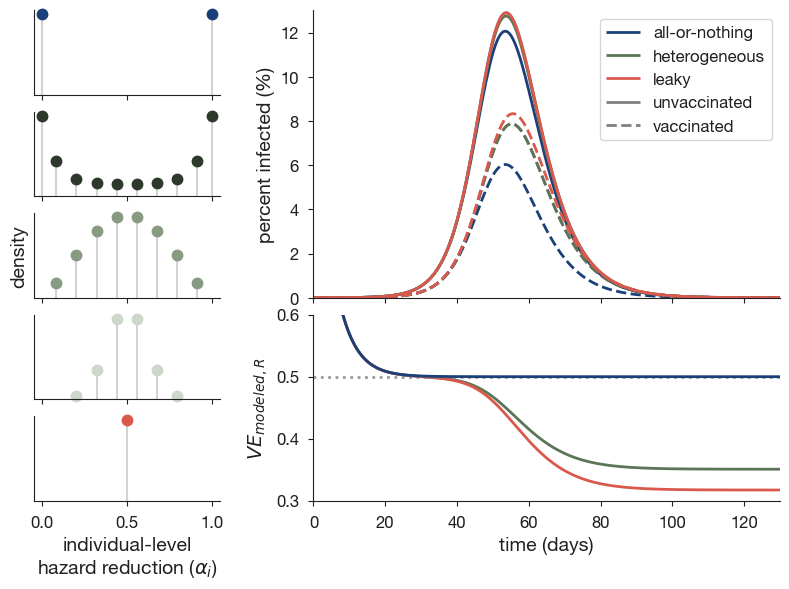

In [106]:
tmax=365
tvals = np.arange(0,tmax+1)
dt=0.5
N = 100000

R0 = 2.2
gamma = 1/4
beta = R0 * gamma
vax_prop = 0.35
VE = 0.5
K=10

concentrations_to_plot = [0.001,0.4,5,20,10000]
cols = [AoN_color,olive_colors[2],olive_colors[5],olive_colors[7],leaky_color]

figure_mosaic = """
0EE
AEE
BEE
CFF
DFF
"""
fig,axes = plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,6))

# Distribution subplots --------------------------------------------------
subplot_labs = ["0","A","B","C","D"]

for ii,conc in enumerate(concentrations_to_plot):
    # Generate vaccine responder classes
    props, VE_levels = generate_vaccine_responder_classes(
        n_classes=K,
        mean_VE=VE,
        concentration=conc
    )
    props[props<=10**(-2)] = None

    # Plot distribution in subplot
    ax = axes[subplot_labs[ii]]
    markerline, stemlines, baseline = ax.stem(VE_levels,props,linefmt="lightgray",\
                                              markerfmt ="o",basefmt="gray")
    markerline.set_color(cols[ii])
    markerline.set_clip_on(False)
    markerline.set_linestyle('None')
    markerline.set_markersize(7.5)
    baseline.set_visible(False)

for ax_lab in subplot_labs:
    ax = axes[ax_lab]
    finalize(ax)
    ax.set_ylim([0,None])
    ax.set_yticks([])
    if ax_lab != "D":
        ax.set_xticklabels([])
axes["B"].set_ylabel("density")
axes["D"].set_xlabel(r"""individual-level
hazard reduction ($\alpha_i$)""")


# ------------------------------------------------------------------------
# -- For all-or-nothing vaccine ------------------------------------------
# ------------------------------------------------------------------------
vax_mech = "all-or-nothing"

# Run SIR dynamics
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech)

# Panel E: epidemic time series ----------------------------------
ax = axes["E"]

ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c=AoN_color,label="all-or-nothing",linewidth=lw)
ax.plot(res['t'],res["VI"]/((vax_prop)*N)*100,c=AoN_color,linestyle="dashed",linewidth=lw)

# Panel F: time-varying VE estimate ----------------------------------
ax = axes["F"]

# get true observed VE
VE_observed = get_observed_VE_direct(res,True)
print("All-or-nothing model final VE = ",VE_observed[-1])
ax.plot(res["t"],VE_observed,c=AoN_color,zorder=3,linewidth=lw)


# ------------------------------------------------------------------------
# -- For heterogeneous model ------------------------------------------
# ------------------------------------------------------------------------
K = 10
# prop_with_VE, VE_levels = generate_vaccine_responder_classes(K,mean_VE=VE,concentration=concentrations_to_plot[2])
# prop_with_VE_total = prop_with_VE * vax_prop

params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop}
inits = initialize_SIR(N)

res = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params,\
                        K=K,mean_VE = VE, concentration=concentrations_to_plot[2],\
                        sigma_correction=False)
VI_total = get_vax_infected_heterogeneous(res)

# Panel E: epidemic time series ----------------------------------
ax = axes["E"]

ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c=heterogeneous_color,label="heterogeneous",linewidth=lw)
ax.plot(res['t'],VI_total/(vax_prop*N)*100,c=heterogeneous_color,linestyle="dashed",linewidth=lw)

# Panel F: time-varying VE estimate ----------------------------------
ax = axes["F"]

# get true observed VE
VE_observed = get_observed_VE_direct_heterogeneous(res,time_varying=True,stratified=False)
print("Heterogeneous model final VE = ",VE_observed[-1])
ax.plot(res["t"],VE_observed,c=heterogeneous_color,linewidth=lw)

# ------------------------------------------------------------------------
# -- For leaky vaccine ------------------------------------------
# ------------------------------------------------------------------------
vax_mech = "leaky"

# Run SIR dynamics
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)

# Panel E: epidemic time series ----------------------------------
ax = axes["E"]

ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c=leaky_color,label="leaky",linewidth=lw)
ax.plot(res['t'],res["VI"]/((vax_prop)*N)*100,c=leaky_color,linestyle="dashed",linewidth=lw)

# ghost plots for legend
ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c="gray",zorder=1,label="unvaccinated",linewidth=lw)
ax.plot(res['t'],VI_total/(vax_prop*N)*100,c="gray",linestyle="dashed",zorder=1,label="vaccinated",linewidth=lw)

ax.set_xlim([0,t_max_plot]); ax.set_ylim([0,inf_max])
ax.legend(fontsize=LEGEND_SIZE)
ax.set_xticklabels([])
ax.set_ylabel("percent infected (%)")
finalize(ax)

# Panel F: time-varying VE estimate ----------------------------------
ax = axes["F"]

# get true observed VE
VE_observed = get_observed_VE_direct(res,True)
print("Leaky model final VE = ",VE_observed[-1])
ax.plot(res["t"],VE_observed,c=leaky_color,linewidth=lw)

ax.plot([0,210],[VE,VE],c="gray",linestyle="dotted",alpha=0.8,linewidth=lw)
# ax.text(1,VE-.007,"vaccine effect\nparameter",c="gray",horizontalalignment='left',verticalalignment='top')

ax.set_xlim([0,t_max_plot]); ax.set_ylim([VE_min,VE_max])
ax.set_xlabel("time (days)"); ax.set_ylabel(VEmod)
finalize(ax)

# Show the plot
plt.tight_layout()
fig.subplots_adjust(wspace=0.5,hspace=.2) # space between columns, rows
plt.savefig("figs/raw/time-varying-VE.jpg",dpi=300,bbox_inches='tight')
plt.show()

# Supp fig: leaky, heterogeneous dynamics

In [9]:
t_max_plot = 110
t_min_plot = 20
lw=2

/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:1126: RuntimeWarning: invalid value encountered in divide
  VE = 1 - (res["VR"]/N_vax)/(res["R"]/N_unvax)


All-or-nothing model final VE =  0.5000027303653645
Leaky model final VE =  0.31713014309475407
Heterogeneous model final VE =  0.48478353721369905
Heterogeneous model final VE =  0.4121393610267551
Heterogeneous model final VE =  0.3507162836936003
Heterogeneous model final VE =  0.3359391552650731
Heterogeneous model final VE =  0.32025824179808926


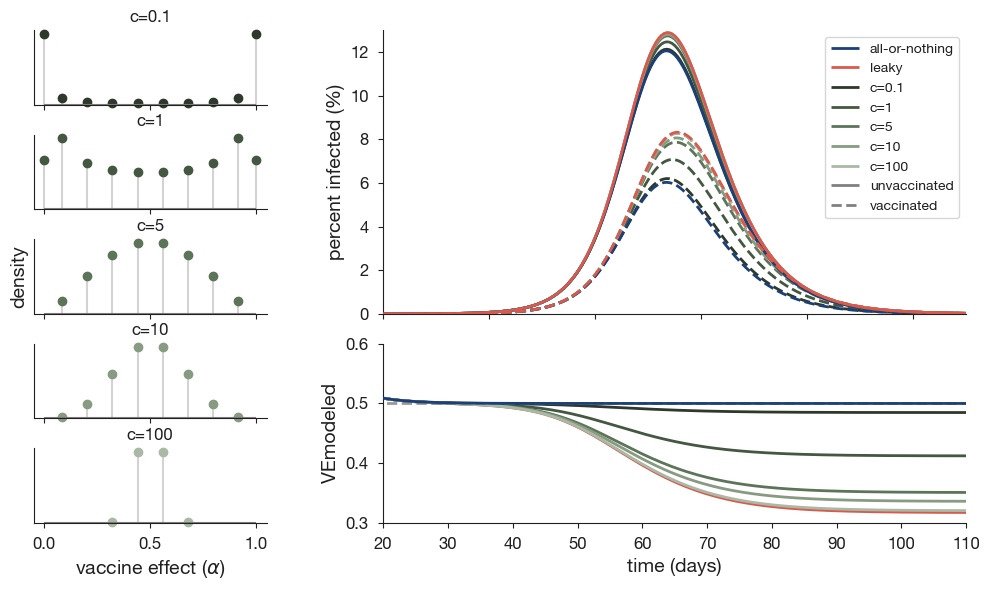

In [10]:
tmax=365
tvals = np.arange(0,tmax+1)
dt=0.5
N = 100000

R0 = 2.2
gamma = 1/4
beta = R0 * gamma
vax_prop = 0.35
VE = 0.5
K=10

concentrations_to_plot = [.1,1,5,10,100]

figure_mosaic = """
0EE
AEE
BEE
CFF
DFF
"""
fig,axes = plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(10,6))

# Distribution subplots --------------------------------------------------
subplot_labs = ["0","A","B","C","D"]
cols = olive_colors[2:]

for ii,conc in enumerate(concentrations_to_plot):
    # Generate vaccine responder classes
    props, VE_levels = generate_vaccine_responder_classes(
        n_classes=K,
        mean_VE=VE,
        concentration=conc
    )
    props[props<=10**(-3)] = None

    # Plot distribution in subplot
    ax = axes[subplot_labs[ii]]
    markerline, stemlines, baseline = ax.stem(VE_levels,props,linefmt="lightgray",\
                                              markerfmt ="o",basefmt="gray")
    markerline.set_color(cols[ii])
    markerline.set_clip_on(False)
    markerline.set_linestyle('None')

    ax.set_title("c={}".format(conc))

for ax_lab in subplot_labs:
    ax = axes[ax_lab]
    finalize(ax)
    ax.set_ylim([0,None])
    ax.set_yticks([])
    if ax_lab != "D":
        ax.set_xticklabels([])
axes["B"].set_ylabel("density")
axes["D"].set_xlabel(r"vaccine effect ($\alpha$)")


# ------------------------------------------------------------------------
# -- For all-or-nothing vaccine ------------------------------------------
# ------------------------------------------------------------------------
vax_mech = "all-or-nothing"

# Run SIR dynamics
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech)

# Panel E: epidemic time series ----------------------------------
ax = axes["E"]

ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c=AoN_color,label="all-or-nothing",linewidth=lw,zorder=3)
ax.plot(res['t'],res["VI"]/((vax_prop)*N)*100,c=AoN_color,linestyle="dashed",linewidth=lw,zorder=3)

# Panel F: time-varying VE estimate ----------------------------------
ax = axes["F"]

# get true observed VE
VE_observed = get_observed_VE_direct(res,True)
print("All-or-nothing model final VE = ",VE_observed[-1])
ax.plot(res["t"],VE_observed,c=AoN_color,zorder=3,linewidth=lw)


# ------------------------------------------------------------------------
# -- For leaky vaccine ------------------------------------------
# ------------------------------------------------------------------------
vax_mech = "leaky"

# Run SIR dynamics
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)

# Panel E: epidemic time series ----------------------------------
ax = axes["E"]

ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c=leaky_color,label="leaky",linewidth=lw,zorder=3)
ax.plot(res['t'],res["VI"]/((vax_prop)*N)*100,c=leaky_color,linestyle="dashed",linewidth=lw,zorder=3)

# Panel F: time-varying VE estimate ----------------------------------
ax = axes["F"]

# get true observed VE
VE_observed = get_observed_VE_direct(res,True)
print("Leaky model final VE = ",VE_observed[-1])
ax.plot(res["t"],VE_observed,c=leaky_color,linewidth=lw)


# ------------------------------------------------------------------------
# -- For heterogeneous model ------------------------------------------
# ------------------------------------------------------------------------
K = 10
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop}
inits = initialize_SIR(N)

for ii,conc in enumerate(concentrations_to_plot):

    res = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params,\
                            K=K,mean_VE = VE, concentration=conc,\
                            sigma_correction=False)
    VI_total = get_vax_infected_heterogeneous(res)

    # Panel E: epidemic time series ----------------------------------
    ax = axes["E"]

    ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c=olive_colors[ii+2],label="c={}".format(conc),linewidth=lw)
    ax.plot(res['t'],VI_total/(vax_prop*N)*100,c=olive_colors[ii+2],linestyle="dashed",linewidth=lw)

    # Panel F: time-varying VE estimate ----------------------------------
    ax = axes["F"]

    VE_observed = get_observed_VE_direct_heterogeneous(res,time_varying=True,stratified=False)
    print("Heterogeneous model final VE = ",VE_observed[-1])
    ax.plot(res["t"],VE_observed,c=olive_colors[ii+2],linewidth=lw)

ax = axes["E"]
# ghost plots for legend
ax.plot(res['t'],res["I"]/((1-vax_prop)*N)*100,c="gray",zorder=1,label="unvaccinated",linewidth=lw)
ax.plot(res['t'],VI_total/(vax_prop*N)*100,c="gray",linestyle="dashed",zorder=1,label="vaccinated",linewidth=lw)
ax.set_xlim([0,t_max_plot]); ax.set_ylim([0,inf_max])
ax.legend()
ax.set_xticklabels([])
ax.set_ylabel("percent infected (%)")
finalize(ax)

ax = axes["F"]
ax.plot([0,210],[VE,VE],c="gray",linestyle="dashed",alpha=0.8,linewidth=lw)
ax.set_xlim([t_min_plot,t_max_plot]); ax.set_ylim([VE_min,VE_max])
ax.set_xlabel("time (days)"); ax.set_ylabel("VEmodeled")
finalize(ax)

# Show the plot 
plt.tight_layout()
fig.subplots_adjust(wspace=0.5,hspace=0.4) # space between columns, rows
plt.savefig("figs/supp-time-varying-VE.jpg",dpi=300,bbox_inches='tight')
plt.show()

## Figure 2
Generate base figure for diagram

/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:1123: RuntimeWarning: invalid value encountered in divide
  VE = 1 - (res["VR"]/N_vax)/(res["R"]/N_unvax)
/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:1123: RuntimeWarning: invalid value encountered in divide
  VE = 1 - (res["VR"]/N_vax)/(res["R"]/N_unvax)


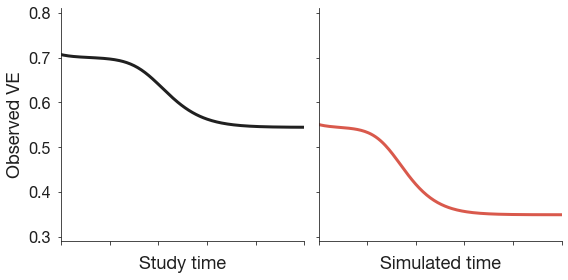

In [19]:
tmax=365
tvals = np.arange(0,tmax+1)
dt=0.5
N = 100000
xmin = 20; xmax = 120

R0 = 2.3
gamma = 1/4
beta = R0 * gamma
vax_prop = 0.35
VE = 0.7

figure_mosaic = """
AB
"""
fig_labs = ["A","B"]
fig,axes = plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,4))

# ------------------------------------------------------------------------
# -- For leaky vaccine ------------------------------------------
# ------------------------------------------------------------------------
vax_mech = "leaky"

# Panel A: measured scenario ----------------------------------
ax = axes["A"]

# Run SIR dynamics
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params, \
               vax_type=vax_mech,leaky_correction=False)

# get observed VE time series
VE_observed = get_observed_VE_direct(res,True)
ax.plot(res["t"],VE_observed,c=ALMOST_BLACK,linewidth=3)

ax.set_xlim([xmin,xmax]); ax.set_xticklabels([])
ax.set_ylim([0.29,0.81])
ax.set_xlabel("Study time")
ax.set_ylabel("Observed VE")
finalize(ax,fontsize=LABEL_SIZE_LARGE)

# Panel B: time-varying VE estimate ----------------------------------
ax = axes["B"]

# Run SIR dynamics with observed VE as VE
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE_observed[-1]}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params, \
               vax_type=vax_mech,leaky_correction=False)

# get observed VE time series
VE_observed = get_observed_VE_direct(res,True)
ax.plot(res["t"],VE_observed,c=c_orange,linewidth=3)

ax.set_xlim([xmin,xmax]); ax.set_xticklabels([])
ax.set_ylim([0.29,0.81]);  ax.set_yticklabels([])
ax.set_xlabel("Simulated time")
finalize(ax,fontsize=LABEL_SIZE_LARGE)

# Show the plot 
plt.tight_layout()
plt.savefig("figs/raw/schematic.jpg",dpi=300,bbox_inches='tight')
plt.show()

## Fig 3

In [16]:
# ============================================
# ISOCLINE PLOT: Heterogeneous model bias
# ============================================

# Approx runtime: 90 seconds

mean_VE_range=(.05, 0.95)
mean_VE_points=40
concentration_range=(0.01, 10000)
concentration_points=80
R0=2.2
gamma=1/4
beta = R0*gamma
vax_prop=0.35
K=51
use_log_concentration=True

# Create grids
mean_VE_vals = np.linspace(mean_VE_range[0], mean_VE_range[1], mean_VE_points)

if use_log_concentration:
    concentration_vals = np.logspace(
        np.log10(concentration_range[0]),
        np.log10(concentration_range[1]),
        concentration_points
    )
else:
    concentration_vals = np.linspace(
        concentration_range[0],
        concentration_range[1],
        concentration_points
    )

# Initialize VEmodeled grid
VEmod_grid = np.zeros((len(mean_VE_vals), len(concentration_vals))) * np.nan

# Compute bias for each combination
for i, mean_ve in enumerate(mean_VE_vals):
    for j, conc in enumerate(concentration_vals):

        # run heterogeneous SIR model - no parameter correction
        param_corr = False
        params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": mean_ve}
        res = run_SIRV_heterogeneous(params=params,
                               K=K, 
                               mean_VE=mean_ve, 
                               concentration=conc, 
                               sigma_correction=param_corr)

        # Calculated modeled VE
        VE_modeled = get_observed_VE_direct_heterogeneous(res,time_varying=False,stratified=False)

        # Record modeled VE
        VEmod_grid[i, j] = VE_modeled


/Users/caseymiddleton/opt/anaconda3/lib/python3.8/site-packages/scipy/stats/_continuous_distns.py:678: RuntimeWarning: divide by zero encountered in _beta_cdf
  return _boost._beta_cdf(x, a, b)


When c=0.01, mean VE=0.2999710606031912
When c=10, mean VE=0.4638692801126759
When c=10000, mean VE=0.48290086945364463


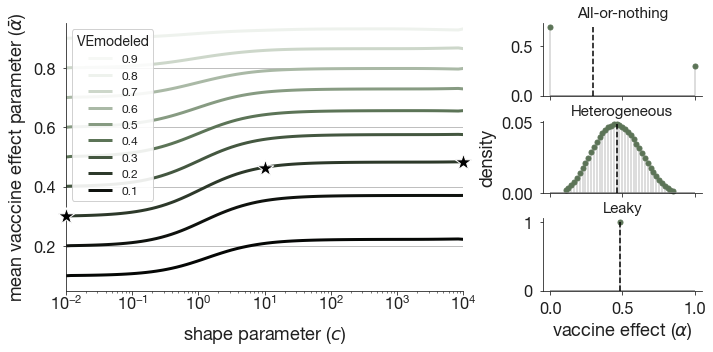

In [26]:
# -------------------------
#    MAKE PLOT
# -------------------------
mean_VE_range=(.05, 0.95)
mean_VE_points=40
concentration_range=(0.01, 10000)
concentration_points=80
R0=2.2
gamma=1/4
beta = R0*gamma
vax_prop=0.35
K=51
use_log_concentration=True

figsize=(10, 12)
figure_mosaic = """
AAB
AAC
AAD
"""
fig_labs = ["A","B","C","D"]
fig,axes = plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(10,5))

# Isocline plot --------------------------------------------------
ax = axes["A"]

# Create meshgrid for contour plot
Concentration, MeanVE = np.meshgrid(concentration_vals, mean_VE_vals)

# Define isocline levels 
isocline_levels = np.linspace(0.1,0.9,9)
isocline_levels_r = np.linspace(0.9,0.1,9)

# Add contour lines at specific levels
contour = ax.contour(Concentration, MeanVE, VEmod_grid,
                     levels=isocline_levels,
                     colors=olive_colors, linewidths=3, alpha=1)

# Create legend using proxy artists (Line2D objects)
from matplotlib.lines import Line2D
legend_elements = []
for i, level in enumerate(isocline_levels_r):
    legend_elements.append(Line2D([0], [0], color=olive_colors[9-i], linewidth=3,
                                  label=f'{level:.1f}'))

ax.legend(handles=legend_elements, title="VEmodeled", loc='upper left', frameon=True, 
          framealpha=0.9, fontsize=LEGEND_SIZE, title_fontsize=LABEL_SIZE)

# Set x-axis scale
if use_log_concentration:
    ax.set_xscale('log')

# Labels
ax.set_xlabel(r'shape parameter ($c$)', fontsize=12, labelpad=12)
ax.set_ylabel(r'mean vacccine effect parameter ($\bar{\alpha}$)', fontsize=12)
finalize(ax,fontsize=LABEL_SIZE_LARGE)
ax.tick_params(axis='x', which='major', pad=-1)

ax.grid(visible=True, which="both", axis="y")


# Distribution subplots --------------------------------------------------
# Find mean_VE values that give VE_modeled = 0.3 at specific concentrations
VEmod_target = 0.3
concentrations_to_plot = [0.01, 10, 10000]
subplot_labs = ["B","C","D"]
titles = ["All-or-nothing","Heterogeneous","Leaky"]
mean_VE_at_concentrations = []

for conc in concentrations_to_plot:
    # Find the index of the concentration closest to our target
    conc_idx = np.argmin(np.abs(concentration_vals - conc))
    
    # Extract the VE_modeled values at this concentration (vertical slice)
    VEmod_at_conc = VEmod_grid[:, conc_idx]
    
    # Find the mean_VE that gives VE_modeled closest to target
    # (interpolate for better accuracy)
    valid_mask = ~np.isnan(VEmod_at_conc)
    if np.any(valid_mask):
        from scipy.interpolate import interp1d
        # Create interpolator (mean_VE as function of VE_modeled)
        f = interp1d(VEmod_at_conc[valid_mask], mean_VE_vals[valid_mask], 
                     bounds_error=False, fill_value='extrapolate')
        mean_ve_solution = f(VEmod_target)
        mean_VE_at_concentrations.append(mean_ve_solution)
    else:
        mean_VE_at_concentrations.append(np.nan)

for ii, (conc, mean_ve) in enumerate(zip(concentrations_to_plot, mean_VE_at_concentrations)):
    # Generate vaccine responder classes
    props, VE_levels = generate_vaccine_responder_classes(
        n_classes=K,
        mean_VE=mean_ve,  # Use the interpolated mean_VE
        concentration=conc
    )

    # Plot star on isocline plot
    axes["A"].scatter(conc, mean_ve, marker="*", c="k", edgecolor="w", linewidth=1, s=300, zorder=3, clip_on=False)
    
    # Plot distribution in subplot
    ax = axes[subplot_labs[ii]]
    props[props<=10**(-2.8)] = None # hide 0's

    markerline, stemlines, baseline = ax.stem(VE_levels,props,linefmt="lightgray",\
                                              markerfmt ="o",basefmt="gray")
    markerline.set_color(olive)
    markerline.set_clip_on(False)
    markerline.set_linestyle('None')
    markerline.set_markersize(5)

    props_no_nan = props
    props_no_nan[np.isnan(props_no_nan)]=0
    ax.plot([mean_ve,mean_ve],[0,max(props_no_nan)],c="k",linestyle="dashed",zorder=10) # plot mean
    print("When c={}, mean VE={}".format(conc,mean_ve))
    
    ax.set_title(titles[ii],size=15)

for ax_lab in subplot_labs:
    ax = axes[ax_lab]
    finalize(ax,fontsize=LABEL_SIZE_LARGE)
    ax.set_ylim([0,None])
    # ax.set_yticks([])
axes["B"].set_xticklabels([]); axes["C"].set_xticklabels([])
axes["C"].set_ylabel("density")
axes["D"].set_xlabel(r"vaccine effect ($\alpha$)")

plt.tight_layout()
fig.subplots_adjust(wspace=0.5,hspace=0.35) # space between columns,rows
plt.savefig("figs/raw/heterogeneous_isoclines.jpg", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# -------------------------
#    HEATMAP: VEmodeled - alpha
# -------------------------

# Compute bias: VEmodeled minus the mean_VE parameter (alpha)
bias_grid = VEmod_grid - mean_VE_vals[:, np.newaxis]

fig, ax = plt.subplots(figsize=(8, 5))

# Build bin edges for pcolormesh (one more edge than cell centers)
log_conc = np.log10(concentration_vals)
log_edges = np.concatenate([
    [log_conc[0]  - (log_conc[1]  - log_conc[0])  / 2],
    (log_conc[:-1] + log_conc[1:]) / 2,
    [log_conc[-1] + (log_conc[-1] - log_conc[-2]) / 2]
])
conc_edges = 10 ** log_edges

dv = mean_VE_vals[1] - mean_VE_vals[0]
ve_edges = np.concatenate([
    [mean_VE_vals[0]  - dv / 2],
    (mean_VE_vals[:-1] + mean_VE_vals[1:]) / 2,
    [mean_VE_vals[-1] + dv / 2]
])

Conc_edges, VE_edges = np.meshgrid(conc_edges, ve_edges)

# Diverging colormap centered at 0
vmax = np.nanmax(np.abs(bias_grid))
im = ax.pcolormesh(Conc_edges, VE_edges, bias_grid,
                   cmap="magma", vmin=-vmax, vmax=0, shading="flat")

# Zero-bias contour for reference
ax.contour(concentration_vals, mean_VE_vals, bias_grid,
           levels=[0], colors="k", linewidths=1.5, linestyles="--")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"Bias ($VE_{modeled,R} - \bar{\alpha}$)", fontsize=12)

ax.set_xscale("log")
ax.set_xlabel(r"shape parameter ($c$)", fontsize=12, labelpad=12)
ax.set_ylabel(r"mean vaccine effect parameter ($\bar{\alpha}$)", fontsize=12)
finalize_keep_frame(ax)
ax.tick_params(axis='x', which='major', pad=-1)

plt.tight_layout()
plt.savefig("figs/raw/Supp_heterogeneous_isoclines.jpg", dpi=300, bbox_inches="tight")
plt.show()


NameError: name 'VEmod_grid' is not defined

## Fig 4

In [6]:
N = 100000
dt = 0.5
gamma = 1/4
vax_mech = "leaky"
inits = initialize_SIR(N)

The next cell takes ~90 minutes. If `output/heatmap_data.npz` already exists, skip it.

In [8]:
# Takes approximately 90 minutes to run
tmax=1000; dt=0.5; N=100000; gamma=1/4; VE=0.7; vax_mech="leaky"
study_R0=2.6; study_beta=study_R0*gamma
R0_vals=[2.1,2.6,3.1]
vax_fracs=np.arange(0.01,1,0.05)
inits=initialize_SIR(N)
all_bias_uncorrected={}; all_bias_corrected={}

for ii,R0 in enumerate(R0_vals):
    beta=R0*gamma
    bias_grid_uncorrected=np.zeros((len(vax_fracs),len(vax_fracs)))*np.nan
    bias_grid_corrected  =np.zeros((len(vax_fracs),len(vax_fracs)))*np.nan
    for jj,study_vax_prop in enumerate(vax_fracs):
        params={"beta":study_beta,"gamma":gamma,"vax_prop":study_vax_prop,"VE":VE}
        res=run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
        VE_observed_TND=get_observed_VE_direct(res,False)
        for kk,model_vax_prop in enumerate(vax_fracs):
            params={"beta":beta,"gamma":gamma,"vax_prop":model_vax_prop,"VE":VE}
            res=run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
            VE_true=get_observed_VE_direct(res,False)
            params={"beta":beta,"gamma":gamma,"vax_prop":model_vax_prop,"VE":VE_observed_TND}
            res=run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
            VE_mod=get_observed_VE_direct(res,False)
            bias_grid_uncorrected[jj,kk]=VE_mod-VE_true
            HIT=get_herd_immunity_threshold(R0,VE_observed_TND)
            try:
                res=run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=True)
                VE_mod=get_observed_VE_direct(res,False)
                bias_grid_corrected[jj,kk]=VE_mod-VE_true
            except:
                print("No solution for R0={}, model={}, study={}".format(R0,model_vax_prop,study_vax_prop))
                bias_grid_corrected[jj,kk]=None
    all_bias_uncorrected[R0]=bias_grid_uncorrected
    all_bias_corrected[R0]=bias_grid_corrected

np.savez("output/heatmap_data.npz",
         R0_vals=R0_vals,vax_fracs=vax_fracs,
         **{f"uncorrected_R0_{R0}": all_bias_uncorrected[R0] for R0 in R0_vals},
         **{f"corrected_R0_{R0}": all_bias_corrected[R0] for R0 in R0_vals})
print("Saved heatmap data to output/heatmap_data.npz")

No solution for R0=2.1, model=0.8600000000000001, study=0.31000000000000005


capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:288: UserWarning: Epidemic not yet complete. 11.751433941121842 infections remaining.
  warnings.warn("Epidemic not yet complete. {} infections remaining.".format(results["I"][-1] + results["VI"][-1]))
/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:288: UserWarning: Epidemic not yet complete. 15.198515789791468 infections remaining.
  warnings.warn("Epidemic not yet complete. {} infections remaining.".format(results["I"][-1] + results["VI"][-1]))
/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:288: UserWarning: Epidemic not yet complete. 15.797095491338535 infections remaining.
  warnings.warn("Epidemic not yet complete. {} infections remaining.".format(results["I"][-1] + results["VI"][-1]))
/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission

Saved heatmap data to output/heatmap_data.npz


/Users/caseymiddleton/Desktop/ActiveProjects/ModMeasVE/env/transmission_functions.py:288: UserWarning: Epidemic not yet complete. 12.00563750430717 infections remaining.
  warnings.warn("Epidemic not yet complete. {} infections remaining.".format(results["I"][-1] + results["VI"][-1]))


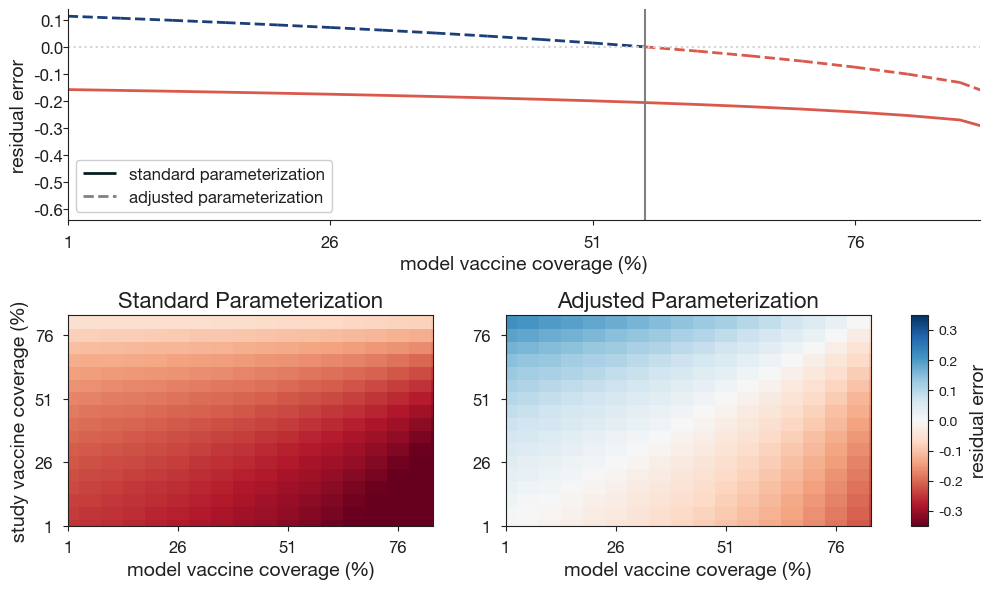

In [9]:
data=np.load("output/heatmap_data.npz")
R0_vals=data["R0_vals"]; vax_fracs=data["vax_fracs"]
R0=2.6

bg_u=data[f"uncorrected_R0_{R0}"]; bg_c=data[f"corrected_R0_{R0}"]

centers=vax_fracs.min(),vax_fracs.max(),vax_fracs.min(),vax_fracs.max()
ticks=[0.01,.26,.51,.76,.96]; ticklabs=[int(t*100) for t in ticks]

figure_mosaic='AAAAAAAAA\nBBBBCCCCL'

fig,axes=plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(10,6))

# plot single study vax coverage scenario
ax=axes["A"]; c_blue="#1B4079"
jj=np.argmin(np.abs(vax_fracs-0.56)); HIT=get_herd_immunity_threshold(R0,0.7)
ax.plot(vax_fracs,bg_u[jj,:],c=c_orange,linestyle='-',linewidth=2)

x=vax_fracs; y=bg_c[jj,:]
for i in range(len(x)-1):
    xi=[x[i],x[i+1]]; yi=[y[i],y[i+1]]
    if y[i]*y[i+1]<0 and not (np.isnan(y[i]) or np.isnan(y[i+1])):
        xc=x[i]+(x[i+1]-x[i])*(-y[i])/(y[i+1]-y[i])
        ax.plot([x[i],xc],[y[i],0],c=c_blue if y[i]>=0 else c_orange,linestyle='dashed',linewidth=2)
        ax.plot([xc,x[i+1]],[0,y[i+1]],c=c_blue if y[i+1]>=0 else c_orange,linestyle='dashed',linewidth=2)
    else:
        midval=(y[i]+y[i+1])/2
        ax.plot(xi,yi,c=c_blue if midval>=0 else c_orange,linestyle='dashed',linewidth=2)

ax.hlines(0,0,1,color="lightgray",linestyle="dotted")
ax.vlines(vax_fracs[jj],-2,2,color="gray")
ax.set_yticks(np.arange(-.6,.15,0.1)); ax.set_xticks(ticks); ax.set_xticklabels(ticklabs)
ax.set_xlim([.01,HIT]); ax.set_ylim([-0.64,.14]); ax.set_ylabel("residual error")
finalize(ax); 
ax.tick_params(axis='y',which='major',pad=-.25)

ax.legend(handles=[Line2D([0],[0],color=almost_black,linestyle='-',linewidth=2,label="standard parameterization"),
                   Line2D([0],[0],color="gray",linestyle='dashed',linewidth=2,label="adjusted parameterization")],
          framealpha=0.95,loc="lower left", fontsize=LEGEND_SIZE)
ax.set_xlabel("model vaccine coverage (%)")

# plot heatmaps across all vaccine coverage scenarios
cmap="RdBu"; vmin=-0.35; vmax=0.35
cmap_obj=plt.get_cmap(cmap).copy(); cmap_obj.set_bad(color="w")

# standard parameterization
ax=axes["B"]
im=ax.imshow(bg_u,aspect='auto',origin='lower',extent=create_extent(bg_u,centers),
             vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation="nearest")

ax.set_xlabel("model vaccine coverage (%)"); ax.set_ylabel("study vaccine coverage (%)")
ax.set_xticks(ticks); ax.set_xticklabels(ticklabs); ax.set_yticks(ticks); ax.set_yticklabels(ticklabs)
ax.set_xlim([0.01,HIT-0.04]); ax.set_ylim([0.01,HIT-0.04])
ax.set_title("Standard Parameterization",size=LABEL_SIZE+2); finalize_keep_frame(ax)

# adjusted parameterization
ax=axes["C"]
im=ax.imshow(bg_c,aspect='auto',origin='lower',extent=create_extent(bg_c,centers),
             vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation="nearest")
ax.set_xlabel("model vaccine coverage (%)")
ax.set_xticks(ticks); ax.set_xticklabels(ticklabs); ax.set_yticks(ticks); ax.set_yticklabels(ticklabs)
ax.set_xlim([0.01,HIT-0.04]); ax.set_ylim([0.01,HIT-0.04])
ax.set_title("Adjusted Parameterization",size=LABEL_SIZE+2); finalize_keep_frame(ax)

cbar=plt.colorbar(im,ax=axes["L"],orientation="vertical",location="right",fraction=1.9,aspect=12)
cbar.set_label("residual error",size=LABEL_SIZE,labelpad=5); remove_ax(axes["L"])
plt.tight_layout(); fig.subplots_adjust(wspace=2,hspace=0.45)
plt.savefig("figs/raw/correction_accuracy.jpg",dpi=300,bbox_inches='tight'); plt.show()

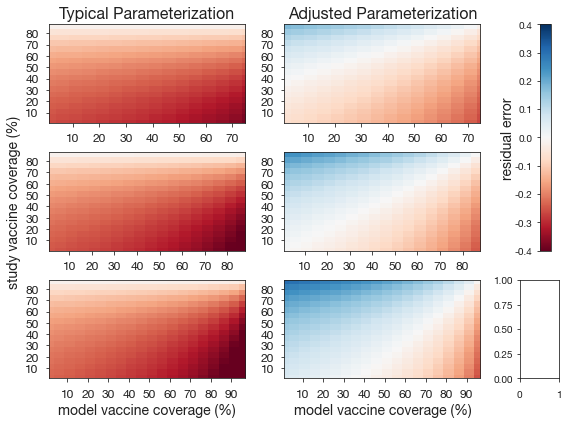

In [ ]:
data=np.load("output/heatmap_data.npz")
R0_vals=data["R0_vals"]; vax_fracs=data["vax_fracs"]

cmap="RdBu"; vmin=-0.4; vmax=0.4
centers=vax_fracs.min(),vax_fracs.max(),vax_fracs.min(),vax_fracs.max()
study_HIT=min(0.99,get_herd_immunity_threshold(2.6,0.7))

ticks=[.1,.2,.3,.4,.5,.6,.7,.8,.9]; yticklabs=[]; ytickmarks=[]
for t in ticks:
    if t<study_HIT:
        yticklabs.append(int(t*100)); ytickmarks.append(t)

ax_index=[["A","B"],["C","D"],["E","F"]]
figure_mosaic='AAABBBL\nCCCDDDL\nEEEFFFl'
fig,axes=plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,6))

cmap_obj=plt.get_cmap(cmap).copy(); cmap_obj.set_bad(color="k")
for ii,R0 in enumerate(R0_vals):
    bg_u=data[f"uncorrected_R0_{R0}"]; bg_c=data[f"corrected_R0_{R0}"]
    HIT=min(get_herd_immunity_threshold(R0,0.7),0.99)
    ticks2=[.1,.2,.3,.4,.5,.6,.7,.8,.9]; tl=[]; tm=[]
    for t in ticks2:
        if t<HIT: tl.append(int(t*100)); tm.append(t)
    extent=create_extent(bg_u,centers)
    ax=axes[ax_index[ii][0]]
    im=ax.imshow(bg_u,aspect='auto',origin='lower',extent=extent,vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation="nearest")
    ax.set_xlim([0.01,HIT]); ax.set_ylim([0.01,study_HIT])
    ax.set_xticks(tm); ax.set_yticks(ytickmarks); ax.set_xticklabels(tl); ax.set_yticklabels(yticklabs)
    ax=axes[ax_index[ii][1]]
    masked=np.ma.masked_invalid(bg_c)
    im=ax.imshow(masked,aspect='auto',origin='lower',extent=extent,vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation="nearest")
    dx_frac=(vax_fracs[-1]-vax_fracs[0])/(len(vax_fracs)-1)
    for row in range(masked.shape[0]):
        for col in range(masked.shape[1]):
            if masked[row,col] is np.ma.masked:
                x=vax_fracs[col]-dx_frac/2; y=vax_fracs[row]-dx_frac/2
                ax.add_patch(Rectangle((x,y),dx_frac,dx_frac,facecolor='white',edgecolor='gray',hatch='///',linewidth=0.5))
    ax.set_xlim([0.01,HIT]); ax.set_ylim([0.01,study_HIT])
    ax.set_xticks(tm); ax.set_yticks(ytickmarks); ax.set_xticklabels(tl); ax.set_yticklabels(yticklabs)

cbar=plt.colorbar(im,ax=axes["L"],orientation="vertical",location="left",fraction=0.8)
cbar.set_label("residual error",size=LABEL_SIZE,labelpad=0)

axes["A"].set_title("Typical Parameterization",size=LABEL_SIZE_LARGE)
axes["B"].set_title("Adjusted Parameterization",size=LABEL_SIZE_LARGE)
for ax_lab in ["E","F"]: axes[ax_lab].set_xlabel("model vaccine coverage (%)")
axes["C"].set_ylabel("study vaccine coverage (%)")
for ax_lab in ["A","B","C","D","E","F"]: finalize_keep_frame(axes[ax_lab])
remove_ax(axes["L"])
plt.tight_layout(); fig.subplots_adjust(wspace=1,hspace=0.3)
plt.savefig("figs/raw/supp_correction_accuracy_heatmap.jpg",dpi=300,bbox_inches='tight'); plt.show()

## Fig 5

The first cell takes ~4 minutes. If `output/heterogeneous_concentration_heatmap.npz` already exists, skip it.

In [ ]:
# Takes approximately 4 minutes to run
tmax=365; dt=0.5; N=100000; gamma=1/4; VE=0.7; vax_prop=0.35; K=50
study_R0=2.6; study_beta=study_R0*gamma
R0_vals=[2.1,2.6,3.1]; inits=initialize_SIR(N); conc_vals=np.logspace(-2,4,10)
all_bias_uncorrected={}; all_bias_corrected={}
for ii,R0 in enumerate(R0_vals):
    beta=R0*gamma
    bg_u=np.zeros((len(conc_vals),len(conc_vals)))*np.nan
    bg_c=np.zeros((len(conc_vals),len(conc_vals)))*np.nan
    for jj,sc in enumerate(conc_vals):
        p={"beta":study_beta,"gamma":gamma,"vax_prop":vax_prop}
        rs=run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=p,K=K,mean_VE=VE,concentration=sc,sigma_correction=False)
        VE_obs=get_observed_VE_direct_heterogeneous(rs,time_varying=False)
        for kk,mc in enumerate(conc_vals):
            p={"beta":beta,"gamma":gamma,"vax_prop":vax_prop}
            rt=run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=p,K=K,mean_VE=VE,concentration=mc,sigma_correction=False)
            VE_true=get_observed_VE_direct_heterogeneous(rt,time_varying=False)
            rm=run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=p,K=K,mean_VE=VE_obs,concentration=mc,sigma_correction=False)
            bg_u[jj,kk]=get_observed_VE_direct_heterogeneous(rm,time_varying=False)-VE_true
            rm=run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=p,K=K,mean_VE=VE_obs,concentration=mc,sigma_correction=True)
            bg_c[jj,kk]=get_observed_VE_direct_heterogeneous(rm,time_varying=False)-VE_true
    all_bias_uncorrected[R0]=bg_u; all_bias_corrected[R0]=bg_c
np.savez("output/heterogeneous_concentration_heatmap.npz",
         R0_vals=R0_vals,conc_vals=conc_vals,
         **{f"uncorrected_R0_{R0}": all_bias_uncorrected[R0] for R0 in R0_vals},
         **{f"corrected_R0_{R0}": all_bias_corrected[R0] for R0 in R0_vals})
print("Saved heatmap data to output/heterogeneous_concentration_heatmap.npz")

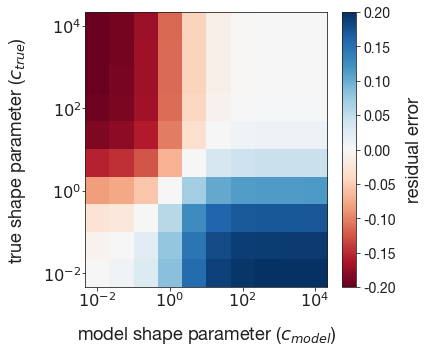

In [32]:
data=np.load("output/heterogeneous_concentration_heatmap.npz")
conc_vals=data["conc_vals"]; R0=2.6
bias_grid=data[f"corrected_R0_{R0}"]

vmin=-0.2; vmax=0.2

cmap_obj=plt.get_cmap("RdBu").copy(); cmap_obj.set_bad(color="lightgray")

fig,ax=plt.subplots(figsize=(6,5))

masked=np.ma.masked_invalid(bias_grid)
im=ax.imshow(masked,aspect='auto',origin='lower',vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation='nearest')

label_exponents=[-2,0,2,4]
tick_positions=[np.argmin(np.abs(np.log10(conc_vals)-exp)) for exp in label_exponents]
tick_labels=[f"$10^{{{exp}}}$" for exp in label_exponents]

ax.set_xticks(tick_positions); ax.set_xticklabels(tick_labels)
ax.set_yticks(tick_positions); ax.set_yticklabels(tick_labels)
ax.set_xlabel(r"model shape parameter ($c_{model}$)",labelpad=15)
ax.set_ylabel(r"true shape parameter ($c_{true}$)",labelpad=15)

cbar=plt.colorbar(im,ax=ax)
cbar.ax.tick_params(labelsize=LABEL_SIZE)
cbar.set_label(r"residual error",size=LABEL_SIZE_LARGE,labelpad=10)

finalize_keep_frame(ax,fontsize=LABEL_SIZE_LARGE)
ax.tick_params(axis='x',which='major',pad=-.52)
ax.tick_params(axis='y',which='major',pad=0.25)

plt.tight_layout()
plt.savefig("figs/raw/heterogeneous_concentration_heatmap.jpg",dpi=300,bbox_inches='tight'); plt.show()

In [ ]:
data=np.load("output/heterogeneous_concentration_heatmap.npz")
conc_vals=data["conc_vals"]; R0_vals=data["R0_vals"]

cmap="RdBu"; vmin=-0.3; vmax=0.3

ax_index=[["A","B"],["C","D"],["E","F"]]
figure_mosaic='AAABBBL\nCCCDDDL\nEEEFFFl'
fig,axes=plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,6))

cmap_obj=plt.get_cmap(cmap).copy(); cmap_obj.set_bad(color="k")
label_exponents=[-2,0,2,4]
tick_positions=[np.argmin(np.abs(np.log10(conc_vals)-exp)) for exp in label_exponents]
tick_labels=[f"$10^{{{exp}}}$" for exp in label_exponents]

for ii,R0 in enumerate(R0_vals):
    bg_u=data[f"uncorrected_R0_{R0}"]; bg_c=data[f"corrected_R0_{R0}"]
    ax=axes[ax_index[ii][0]]
    im=ax.imshow(bg_u,aspect='auto',origin='lower',vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation="nearest")
    ax.set_xticks(tick_positions); ax.set_yticks(tick_positions); ax.set_xticklabels([]); ax.set_yticklabels([])
    ax=axes[ax_index[ii][1]]
    im=ax.imshow(bg_c,aspect='auto',origin='lower',vmin=vmin,vmax=vmax,cmap=cmap_obj,interpolation="nearest")
    ax.set_xticks(tick_positions); ax.set_yticks(tick_positions); ax.set_xticklabels([]); ax.set_yticklabels([])

cbar=plt.colorbar(im,ax=axes["L"],orientation="vertical",location="left",fraction=0.8)
cbar.set_label("residual error",size=LABEL_SIZE,labelpad=-5)

axes["A"].set_title("Typical Parameterization",size=LABEL_SIZE+2)
axes["B"].set_title("Adjusted Parameterization",size=LABEL_SIZE+2)

for ax_lab in ["E","F"]: axes[ax_lab].set_xlabel(r"model shape parameter ($c_{model}$)")
axes["C"].set_ylabel(r"true shape parameter ($c_{true}$)")
for ax_lab in ["A","C","E"]: axes[ax_lab].set_yticklabels(tick_labels)
for ax_lab in ["E","F"]: axes[ax_lab].set_xticklabels(tick_labels)
for ax_lab in ["A","B","C","D","E","F"]: finalize_keep_frame(axes[ax_lab])
remove_ax(axes["L"])

plt.tight_layout(); fig.subplots_adjust(wspace=0.5,hspace=0.2)
plt.savefig("figs/raw/supp_heterogeneous_correction_heatmaps.jpg",dpi=300,bbox_inches='tight'); plt.show()

## Fig 6

In [107]:
pathogens=["pertussis","influenza","COVID-19"]

R0_vals_dict={"pertussis":14,"influenza":2,"COVID-19":5}
VE_vals_dict={"pertussis":0.75,"influenza":0.5,"COVID-19":0.85}
HITs={p: get_herd_immunity_threshold(R0_vals_dict[p],VE_vals_dict[p]) for p in pathogens}

gamma=1/4; vax_props=np.arange(0.01,0.95,0.05)
adjusted_HITs={}
for pathogen in pathogens:
    R0=R0_vals_dict[pathogen]; VE=VE_vals_dict[pathogen]; study_beta=R0*gamma
    pathogen_adjusted_HIT=[]
    for vax_prop in vax_props:
        alpha_adj=solve_sigma_for_target_VE(study_beta,1/gamma,vax_prop,VE)
        pathogen_adjusted_HIT.append(min(get_herd_immunity_threshold(R0,alpha_adj),1.01))
    adjusted_HITs[pathogen]=pathogen_adjusted_HIT

Heterogeneous (c=0.4), no vaccination: 79681.55527048312
Heterogeneous (c=0.4), standard paremeterization: 30184.580786789196
Heterogeneous (c=0.4), adjusted parameterization: 29141.954459556237
Heterogeneous (c=20), no vaccination: 79681.55527048312
Heterogeneous (c=20), standard paremeterization: 32706.688241280834
Heterogeneous (c=20), adjusted parameterization: 29142.05447834712
Leaky, no vaccination: 79681.55527048312
Leaky, standard paremeterization: 32912.684518736234
Leaky, adjusted parameterization: 29142.064166563538


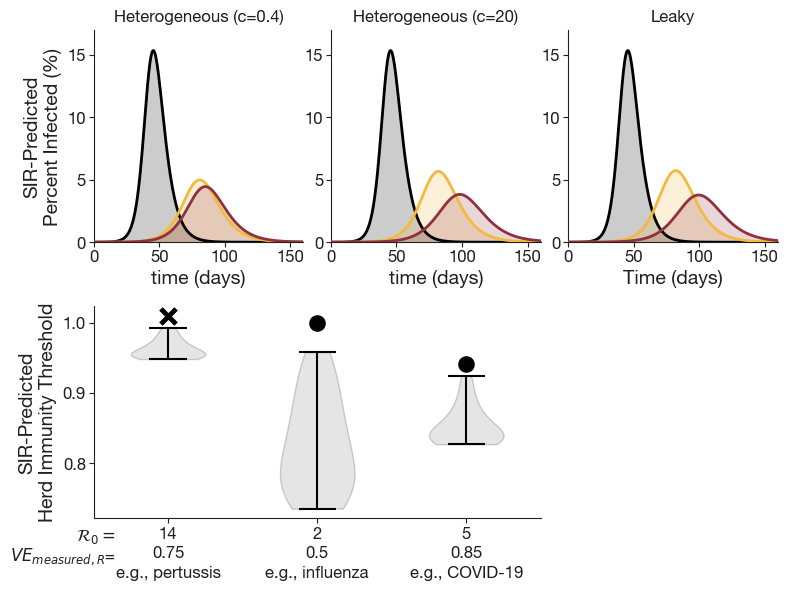

In [111]:
R0 = R0_vals_dict["influenza"]
VE = VE_vals_dict["influenza"]
gamma=1/4; vax_prop=0.5
beta = R0*gamma

tmax=365
tvals = np.arange(0,tmax+1)
dt=0.5
N = 100000
inits = initialize_SIR(N)

lw=2
t_max_plot = 160; inf_max = 17
standard_col = "#F2BA40"
adjusted_col = "#90323D"

figure_mosaic = """
AABBCC
DDDD..
"""
fig,axes=plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,6))

# ------------------------------------------------------------------------
# -- Disease Burden (subplots A-C) ------------------------------------------
# ------------------------------------------------------------------------

# -- For heterogeneous vaccine -----------------------------------------------------------------------------
K = 10

# closer to all-or-nothing --------------------------------------------------------------------------
c = 0.4
ax = axes["A"]

params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop}
params_no_vax = {"beta": beta, "gamma": gamma, "vax_prop": 0}

res_no_vax = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params_no_vax,\
                        K=K, mean_VE = VE, concentration=c, sigma_correction=False)
total_inf_no_vax = get_vax_infected_heterogeneous(res_no_vax) + res_no_vax["I"]
res_standard = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params,\
                        K=K, mean_VE = VE, concentration=c, sigma_correction=False)
total_inf_standard = get_vax_infected_heterogeneous(res_standard) + res_standard["I"]
res_adjusted = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params,\
                        K=K, mean_VE = VE, concentration=c, sigma_correction=True)
total_inf_adjusted = get_vax_infected_heterogeneous(res_adjusted) + res_adjusted["I"]

# epidemic time series
ax.plot(res_no_vax['t'],total_inf_no_vax/N*100,c="k",label="no vaccination",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],total_inf_no_vax/N*100,0,color="k",alpha=0.2)

ax.plot(res_no_vax['t'],total_inf_standard/N*100,c=standard_col,label="standard parameterization",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],total_inf_standard/N*100,0,color=standard_col,alpha=0.2)

ax.plot(res_no_vax['t'],total_inf_adjusted/N*100,c=adjusted_col,label="adjusted parameterization",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],total_inf_adjusted/N*100,0,color=adjusted_col,alpha=0.2)

ax.set_xlim([0,t_max_plot]); ax.set_ylim([0,inf_max])
# ax.legend(fontsize=LEGEND_SIZE)
ax.set_ylabel("SIR-Predicted\nPercent Infected (%)")
ax.set_xlabel("time (days)",labelpad=3)
ax.set_title("Heterogeneous (c={})".format(c))
finalize(ax)
ax.tick_params(pad=2)

# Print total number of infections
print("Heterogeneous (c={}), no vaccination: {}".format(c,res_no_vax["R"][-1]))
print("Heterogeneous (c={}), standard paremeterization: {}".format(c,res_standard["R"][-1]))
print("Heterogeneous (c={}), adjusted parameterization: {}".format(c,res_adjusted["R"][-1]))

# Closer to leaky --------------------------------------------------------------------------
c = 20
col = olive_colors[6]
ax = axes["B"]

params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop}
params_no_vax = {"beta": beta, "gamma": gamma, "vax_prop": 0}

res_no_vax = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params_no_vax,\
                        K=K, mean_VE = VE, concentration=c, sigma_correction=False)
total_inf_no_vax = get_vax_infected_heterogeneous(res_no_vax) + res_no_vax["I"]
res_standard = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params,\
                        K=K, mean_VE = VE, concentration=c, sigma_correction=False)
total_inf_standard = get_vax_infected_heterogeneous(res_standard) + res_standard["I"]
res_adjusted = run_SIRV_heterogeneous(tmax=tmax,dt=dt,inits=inits,params=params,\
                        K=K, mean_VE = VE, concentration=c, sigma_correction=True)
total_inf_adjusted = get_vax_infected_heterogeneous(res_adjusted) + res_adjusted["I"]

# epidemic time series 
ax.plot(res_no_vax['t'],total_inf_no_vax/N*100,c="k",label="no vaccination",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],total_inf_no_vax/N*100,0,color="k",alpha=0.2)

ax.plot(res_no_vax['t'],total_inf_standard/N*100,c=standard_col,label="standard parameterization",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],total_inf_standard/N*100,0,color=standard_col,alpha=0.2)

ax.plot(res_no_vax['t'],total_inf_adjusted/N*100,c=adjusted_col,label="adjusted parameterization",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],total_inf_adjusted/N*100,0,color=adjusted_col,alpha=0.2)

ax.set_xlim([0,t_max_plot]); ax.set_ylim([0,inf_max])
# ax.legend(fontsize=LEGEND_SIZE)
ax.set_xlabel("time (days)",labelpad=3)
ax.set_title("Heterogeneous (c={})".format(c))
finalize(ax)
ax.tick_params(pad=2)

# Print total number of infections
print("Heterogeneous (c={}), no vaccination: {}".format(c,res_no_vax["R"][-1]))
print("Heterogeneous (c={}), standard paremeterization: {}".format(c,res_standard["R"][-1]))
print("Heterogeneous (c={}), adjusted parameterization: {}".format(c,res_adjusted["R"][-1]))


# -- For leaky vaccine ------------------------------------------
vax_mech = "leaky"
ax = axes["C"]

# Run SIR dynamics
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
params_no_vax = {"beta": beta, "gamma": gamma, "vax_prop": 0, "VE": VE}
inits = initialize_SIR(N)

res_no_vax = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params_no_vax,vax_type=vax_mech,leaky_correction=False)
res_standard = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
res_adjusted = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=True)

# infected time series ----------------------------------
ax.plot(res_no_vax['t'],(res_no_vax["I"]+res_no_vax["VI"])/N*100,c="k",label="no vaccination",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],(res_no_vax["I"]+res_no_vax["VI"])/N*100,0,color="k",alpha=0.2)

ax.plot(res_no_vax['t'],(res_standard["I"]+res_standard["VI"])/N*100,c=standard_col,label="standard parameterization",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],(res_standard["I"]+res_standard["VI"])/N*100,0,color=standard_col,alpha=0.2)

ax.plot(res_no_vax['t'],(res_adjusted["I"]+res_adjusted["VI"])/N*100,c=adjusted_col,label="adjusted parameterization",linewidth=lw,zorder=3)
ax.fill_between(res_no_vax['t'],(res_adjusted["I"]+res_adjusted["VI"])/N*100,0,color=adjusted_col,alpha=0.2)

ax.set_xlim([0,t_max_plot]); ax.set_ylim([0,inf_max])
# ax.legend(fontsize=LEGEND_SIZE)
ax.set_xlabel("Time (days)",labelpad=3)
ax.set_title("Leaky")
finalize(ax)
ax.tick_params(pad=2)

# Print total number of infections
print("Leaky, no vaccination: {}".format(res_no_vax["R"][-1]))
print("Leaky, standard paremeterization: {}".format(res_standard["R"][-1]))
print("Leaky, adjusted parameterization: {}".format(res_adjusted["R"][-1]))


# ------------------------------------------------------------------------
# -- Herd Immunity Threshold (subplot D) ------------------------------------------
# ------------------------------------------------------------------------

pathogen_cols=[ALMOST_BLACK,ALMOST_BLACK,ALMOST_BLACK]
pathogen_xvals=[1,2,3]; psize=120
ax = axes["D"]

# Leaky vaccine ------------------------------------------
col = "k"
for ii,pathogen in enumerate(pathogens):
    x=pathogen_xvals[ii]; 
    if HITs[pathogen]<=1:
        ax.scatter(x,HITs[pathogen],c=col,edgecolor="k",s=psize,zorder=3)
    else:
        ax.scatter(x,1.01,marker="x",c=col,s=psize,zorder=3,linewidths=3.5)

    alts=np.array(adjusted_HITs[pathogen])
    q25,q75=np.percentile(alts,[25,75]); iqr=q75-q25
    wlo=max(alts.min(),q25-1.5*iqr); whi=min(alts.max(),q75+1.5*iqr)

    # ax.plot([x,x],[wlo,whi],color=col,linewidth=1.5,zorder=2)
    # ax.plot([x-0.07,x+0.07],[wlo,wlo],color=col,linewidth=1.5,zorder=2)
    # ax.plot([x-0.07,x+0.07],[whi,whi],color=col,linewidth=1.5,zorder=2)
    parts = ax.violinplot(adjusted_HITs[pathogen],[x])
    for pc in parts['bodies']:
        pc.set_facecolor('gray')
        pc.set_edgecolor(ALMOST_BLACK)
        pc.set_alpha(0.2)
    parts['cbars'].set_color('black')       # Center lines
    parts['cmins'].set_color('black')       # Bottom whiskers
    parts['cmaxes'].set_color('black')      # Top whiskers

ax.set_xlim([0.5,3.5]); ax.set_xticks(pathogen_xvals); ax.set_xticklabels([])
ax.set_ylabel("SIR-Predicted\nHerd Immunity Threshold")

trans=blended_transform_factory(ax.transData,ax.transAxes)
y_r0=-0.04; y_ve=-0.13; y_eg=-0.22; fs=LABEL_SIZE_LARGE-4
for ii,pathogen in enumerate(pathogens):
    x=pathogen_xvals[ii]
    ax.text(x,y_r0,str(R0_vals_dict[pathogen]),transform=trans,ha='center',va='top',clip_on=False, size=LABEL_SIZE-2)
    ax.text(x,y_ve,str(VE_vals_dict[pathogen]),transform=trans,ha='center',va='top',clip_on=False, size=LABEL_SIZE-2)
    lab='e.g., influenza' if pathogen=='influenza' else f'e.g., {pathogen}'
    ax.text(x,y_eg,lab,transform=trans,ha='center',va='top',clip_on=False,fontstyle='italic', size=LABEL_SIZE-2)

row_label_x=0.05
ax.text(row_label_x,y_r0,r'$\mathcal{R}_0=$',transform=ax.transAxes,ha='right',va='top',clip_on=False, size=LABEL_SIZE-2)
ax.text(row_label_x,y_ve,VEmeas+"=",transform=ax.transAxes,ha='right',va='top',clip_on=False, size=LABEL_SIZE-2)
finalize(ax)
ax.tick_params(pad=2)

plt.tight_layout()
plt.subplots_adjust(hspace=0.3,wspace=0.3)
plt.savefig("figs/raw/HIT.jpg",dpi=300,bbox_inches='tight'); plt.show()
plt.show()

In [ ]:
# Compute HIT heatmap grids
R0_vals_scan=np.arange(1.1,17.5,0.5); VE_vals_scan=np.arange(0.3,0.99,0.05)
vax_prop=0.01; tau=1
hm_u=np.zeros((len(R0_vals_scan),len(VE_vals_scan)))*np.nan
hm_c=np.zeros((len(R0_vals_scan),len(VE_vals_scan)))*np.nan
for ii,R0 in enumerate(R0_vals_scan):
    for jj,VE in enumerate(VE_vals_scan):
        HIT=get_herd_immunity_threshold(R0,VE)
        hm_u[ii,jj]=None if HIT>1 else HIT
        alpha_adj=solve_sigma_for_target_VE(R0,tau,vax_prop,VE)
        HIT_adj=get_herd_immunity_threshold(R0,alpha_adj)
        hm_c[ii,jj]=None if HIT_adj>1 else HIT_adj

In [ ]:
vmin=0.6; vmax=1
cmap_obj=plt.get_cmap("gist_gray_r").copy(); cmap_obj.set_bad(color="k")
centers=VE_vals_scan.min(),VE_vals_scan.max(),R0_vals_scan.min(),R0_vals_scan.max()
extent=create_extent(hm_u,centers)
figure_mosaic='LL\nAB\nAB\nAB\nAB'
fig,axes=plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,5))
dx=(VE_vals_scan[-1]-VE_vals_scan[0])/(len(VE_vals_scan)-1)
dy=(R0_vals_scan[-1]-R0_vals_scan[0])/(len(R0_vals_scan)-1)
for side,hm in [("A",hm_u),("B",hm_c)]:
    ax=axes[side]
    masked=np.ma.masked_invalid(hm)
    im=ax.imshow(masked,aspect='auto',origin='lower',vmin=vmin,vmax=vmax,
                 cmap=cmap_obj,interpolation='nearest',extent=extent)
    for row in range(masked.shape[0]):
        for col in range(masked.shape[1]):
            if masked[row,col] is np.ma.masked:
                x=VE_vals_scan[col]-dx/2; y=R0_vals_scan[row]-dy/2
                ax.add_patch(Rectangle((x,y),dx,dy,facecolor="w",edgecolor='gray',hatch='///',linewidth=0.5))
    ax.set_xlabel(VEmeas)
    ax.set_xticks([.3,.4,.5,.6,.7,.8,.9]); ax.set_ylim(1.4,12.8)
    finalize_keep_frame(ax)
axes["A"].set_ylabel(r"$R_0$, basic reproduction number")
axes["A"].set_title("Standard Parameterization",size=LABEL_SIZE)
axes["B"].set_title("Adjusted Parameterization",size=LABEL_SIZE)
axes["B"].set_yticklabels([])
cbar=plt.colorbar(im,ax=axes["L"],orientation="horizontal",location="top",fraction=0.4,aspect=30)
cbar.set_label(r"SIR-predicted herd immunity threshold",size=LABEL_SIZE,labelpad=8)
remove_ax(axes["L"])
plt.tight_layout(); fig.subplots_adjust(wspace=0.1,hspace=0)
plt.savefig("figs/raw/HIT_heatmap.jpg",dpi=300,bbox_inches='tight'); plt.show()

# Other supplemental Figures

All-or-nothing model final VE =  0.7
Heterogeneous model final VE =  0.7001411573695864
Leaky model final VE =  0.6999999999999997
All-or-nothing model final VE =  0.7
Heterogeneous model final VE =  0.6155344467009514
Leaky model final VE =  0.5968567766352058
All-or-nothing model final VE =  0.7
Heterogeneous model final VE =  0.5227192078314586
Leaky model final VE =  0.48065399279590315


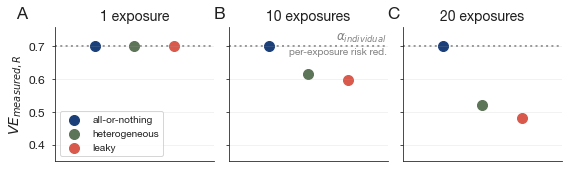

In [ ]:
lw=2
num_exposures = [1,10,20]
pr_inf_per_exposure = 0.1
VE = 0.7

VE_min = 0.35; VE_max = 0.76
ssize = 100

cols = [AoN_color,olive,leaky_color]

figure_mosaic = """
ABC
"""
fig,axes = plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,2.5))

subplot_labs = ["A","B","C"]
exposure_labs = ["exposure","exposures","exposures"]

axes["A"].set_ylabel(VEmeas)

for ii,n_exposures in enumerate(num_exposures):
    ax = axes[subplot_labs[ii]]

    # ------------------------------------------------------------------------
    # -- For all-or-nothing vaccine ------------------------------------------
    # ------------------------------------------------------------------------
    vax_mech = "all-or-nothing"

    VE_observed = get_VE_binomial(n_exposures,pr_inf_per_exposure,VE,vax_mech)
    print("All-or-nothing model final VE = ",VE_observed)
    ax.scatter(1,VE_observed,c=AoN_color,s=ssize,label="all-or-nothing")

    # ------------------------------------------------------------------------
    # -- For heterogeneous model ------------------------------------------
    # ------------------------------------------------------------------------
    conc = 5
    # prop_with_VE, VE_levels = generate_vaccine_responder_classes(K,mean_VE=VE,concentration=concentrations_to_plot[2])
    # prop_with_VE_total = prop_with_VE * vax_prop

    vax_mech = "heterogeneous"

    VE_observed = get_VE_binomial(n_exposures,pr_inf_per_exposure,VE,vax_mech,conc)
    print("Heterogeneous model final VE = ",VE_observed)
    ax.scatter(2,VE_observed,c=heterogeneous_color,s=ssize,label="heterogeneous")

    # ------------------------------------------------------------------------
    # -- For leaky vaccine ------------------------------------------
    # ------------------------------------------------------------------------
    vax_mech = "leaky"

    VE_observed = get_VE_binomial(n_exposures,pr_inf_per_exposure,VE,vax_mech)
    print("Leaky model final VE = ",VE_observed)
    ax.scatter(3,VE_observed,c=leaky_color,s=ssize,label="leaky")


    ax.plot([0,4],[VE,VE],c="gray",linestyle="dotted",alpha=0.8,linewidth=lw,zorder=0)
    ax.set_title("{} {}".format(n_exposures,exposure_labs[ii]),size=LABEL_SIZE)
    ax.set_xlim([0,4]); ax.set_xticks([])
    ax.set_ylim([VE_min,VE_max])
    finalize(ax)
    ax.grid(visible=True,axis="y",which="major",alpha=0.2)

axes["A"].legend()
axes["B"].text(2.7,VE+.02,r"$\alpha_{individual}$",c="gray",size=LABEL_SIZE-2)
axes["B"].text(1.5,VE-.03,"per-exposure risk red.",c="gray")
axes["B"].set_yticklabels([]); axes["C"].set_yticklabels([])

label_subplots(axes,x_pads=(-0.25,-0.1,-0.1))

# Show the plot 
plt.tight_layout()
fig.subplots_adjust(wspace=0.1) # space between columns
plt.savefig("figs/VE_bias_scatter.jpg",dpi=300,bbox_inches='tight')
plt.show()

In [142]:
# ============================================
# HEAT MAP: how vaccinated fraction + VE impact bias
# ============================================

pr_inf_per_exposure = 0.1
vax_mech = "leaky"

# grid
exposures = np.arange(1,16)     # x-axis
alpha_vals = np.arange(0,1.05,0.05)  # y-axis (true VE)

bias_grid = np.zeros((len(alpha_vals), len(exposures))) * np.nan

for i, alpha in enumerate(alpha_vals):
    for j, n_exposures in enumerate(exposures):

        VE_observed = get_VE_binomial(n_exposures,pr_inf_per_exposure,alpha,vax_mech)
        bias_grid[i, j] = VE_observed - alpha

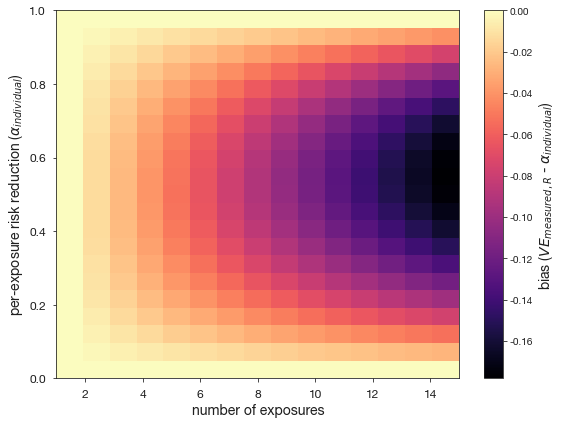

In [153]:
fig, ax = plt.subplots(figsize=(8, 6))

# Mask NaNs (HIT region)
masked = np.ma.masked_invalid(bias_grid)

im = ax.imshow(masked, 
               aspect='auto', 
               origin='lower',
               extent=[exposures.min(), exposures.max(),
                       alpha_vals.min(), alpha_vals.max()],
               cmap="magma")

cbar = plt.colorbar(im, ax=ax)
a_ind = r"$\alpha_{individual}$"
cbar.set_label("bias ({} - {})".format(VEmeas,a_ind),size=LABEL_SIZE)

ax.set_xlabel(r"number of exposures")
ax.set_ylabel(r"per-exposure risk reduction ($\alpha_{{{individual}}}$)")
# ax.set_title("Bias in VEmodeled across vaccination levels and true VE")
finalize_keep_frame(ax)

plt.tight_layout()
plt.savefig("figs/Supp_leaky_bias_heatmap_binomial.jpg",dpi=300,bbox_inches='tight')
plt.show()


In [ ]:
tmax=30*6
dt=0.5
N = 100000
R0 = 2.6
gamma = 1/4
beta = R0 * gamma
VE = 0.7
vax_mech = "leaky"
vax_prop = 0.65

figure_mosaic = 'ABC\nDEF'
fig,axes = plt.subplot_mosaic(mosaic=figure_mosaic,figsize=(8,5))

ax = axes["A"]
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
VE_observed = get_observed_VE_direct(res,True)
ax.plot(res["t"],VE_observed,c=olive,linewidth=3)

ax = axes["B"]
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
time_categories = np.arange(0,tmax+1,20)
cox_results = estimate_VE_cox_tvi(res, time_categories)
VE_cox_by_time = cox_results["VE_by_time_category"]
time_categories = cox_results["time_categories"]
for t_cat in time_categories[1:-1]:
    ax.axvline(t_cat, color="gray", linestyle=':', linewidth=1, alpha=0.4)
ax.plot(time_categories[1:], VE_cox_by_time, c=olive, marker="o", linewidth=3)

ax = axes["C"]
vax_N = N*vax_prop; unvax_N = N*(1-vax_prop)
baseline_inf_prob = 0.7
unvax_infs = unvax_N*baseline_inf_prob
vax_infs = vax_N*baseline_inf_prob*(1-VE)
VE_observed = 1 - (vax_infs/vax_N)/(unvax_infs/unvax_N)
ax.scatter(tmax/4,VE_observed,c=olive,s=100)

for ax_lab in ["A","B","C"]:
    ax = axes[ax_lab]
    ax.plot([0,tmax],[VE,VE],c="gray",linestyle="dashed",alpha=0.6,zorder=0)
    ax.set_ylim(0.5,0.9); ax.set_xlim(0,tmax); ax.set_xticklabels([])
    finalize(ax)
axes["A"].set_ylabel("VEmeasured")
axes["B"].set_yticklabels([]); axes["C"].set_yticklabels([])
axes["A"].set_title("Cumulative Attack Rate",size=LABEL_SIZE)
axes["B"].set_title("Cox Proportional Hazards",size=LABEL_SIZE)
axes["C"].set_title("Challenge Study",size=LABEL_SIZE)

vax_mech = "all-or-nothing"
ax = axes["D"]
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
VE_observed = get_observed_VE_direct(res,True)
ax.plot(res["t"],VE_observed,c=c_orange,linewidth=3)

ax = axes["E"]
params = {"beta": beta, "gamma": gamma, "vax_prop": vax_prop, "VE": VE}
inits = initialize_SIR(N)
res = run_SIRV(tmax=tmax,dt=dt,inits=inits,params=params,vax_type=vax_mech,leaky_correction=False)
time_categories = np.arange(0,tmax+1,20)
cox_results = estimate_VE_cox_tvi(res, time_categories)
VE_cox_by_time = cox_results["VE_by_time_category"]
time_categories = cox_results["time_categories"]
for t_cat in time_categories[1:-1]:
    ax.axvline(t_cat, color="gray", linestyle=':', linewidth=1, alpha=0.4)
ax.plot(time_categories[1:], VE_cox_by_time, c=c_orange, marker="o", linewidth=3)

ax = axes["F"]
vax_N = N*vax_prop; unvax_N = N*(1-vax_prop)
baseline_inf_prob = 0.7
unvax_infs = unvax_N*baseline_inf_prob
vax_infs = vax_N*baseline_inf_prob*(1-VE)
VE_observed = 1 - (vax_infs/vax_N)/(unvax_infs/unvax_N)
ax.scatter(tmax/4,VE_observed,c=c_orange,s=100)

for ax_lab in ["D","E","F"]:
    ax = axes[ax_lab]
    ax.plot([0,tmax],[VE,VE],c="gray",linestyle="dashed",alpha=0.6,zorder=0)
    ax.set_ylim(0.5,0.9); ax.set_xlim(0,tmax); ax.set_xlabel("time (days)")
    finalize(ax)
axes["D"].set_ylabel("VEmeasured")
axes["E"].set_yticklabels([]); axes["F"].set_yticklabels([])

plt.tight_layout()
fig.subplots_adjust(wspace=0.1,hspace=0.1)
plt.savefig("figs/raw/study_design.jpg",dpi=300,bbox_inches='tight')
plt.show()